# **LABORATORIO DE PROCESAMIENTO DIGITAL DE IMAGENES (PDI)**

Pablo Andres Villareal Cardenas - 2043233

Alan Zahir Lopez Rodriguez - 2103115


# **PRÁCTICA 6. *OPERACIONES ARITMÉTICAS Y LÓGICAS***

---

**Importación de librerías y carga de las imágenes**

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar las imágenes en escala de grises (pt 1)
img_a = cv2.imread('/content/rm.png', cv2.IMREAD_GRAYSCALE)
img_b = cv2.imread('/content/radiografia.jpg', cv2.IMREAD_GRAYSCALE)

# Aplicar un resize para que ambas tengan la misma resolución y poder operarlas elemento a elemento
h, w = img_a.shape
img_b = cv2.resize(img_b, (w, h))

> Se importan las librerías necesarias para la práctica: `cv2` (OpenCV) para las operaciones de procesamiento de imágenes, `numpy` para el manejo de matrices y `matplotlib.pyplot` para la visualización de resultados.

> Las imágenes médicas se cargan directamente en escala de grises mediante la bandera `cv2.IMREAD_GRAYSCALE`. Dado que las operaciones aritméticas de la Parte I (suma, resta y multiplicación) requieren que ambas matrices tengan exactamente las mismas dimensiones, se utilizó `cv2.resize` para ajustar `img_b` al mismo tamaño que `img_a` (`w`, `h`).

# **Parte I. Operaciones aritméticas**

**Ejercicio 1: Suma de imágenes**

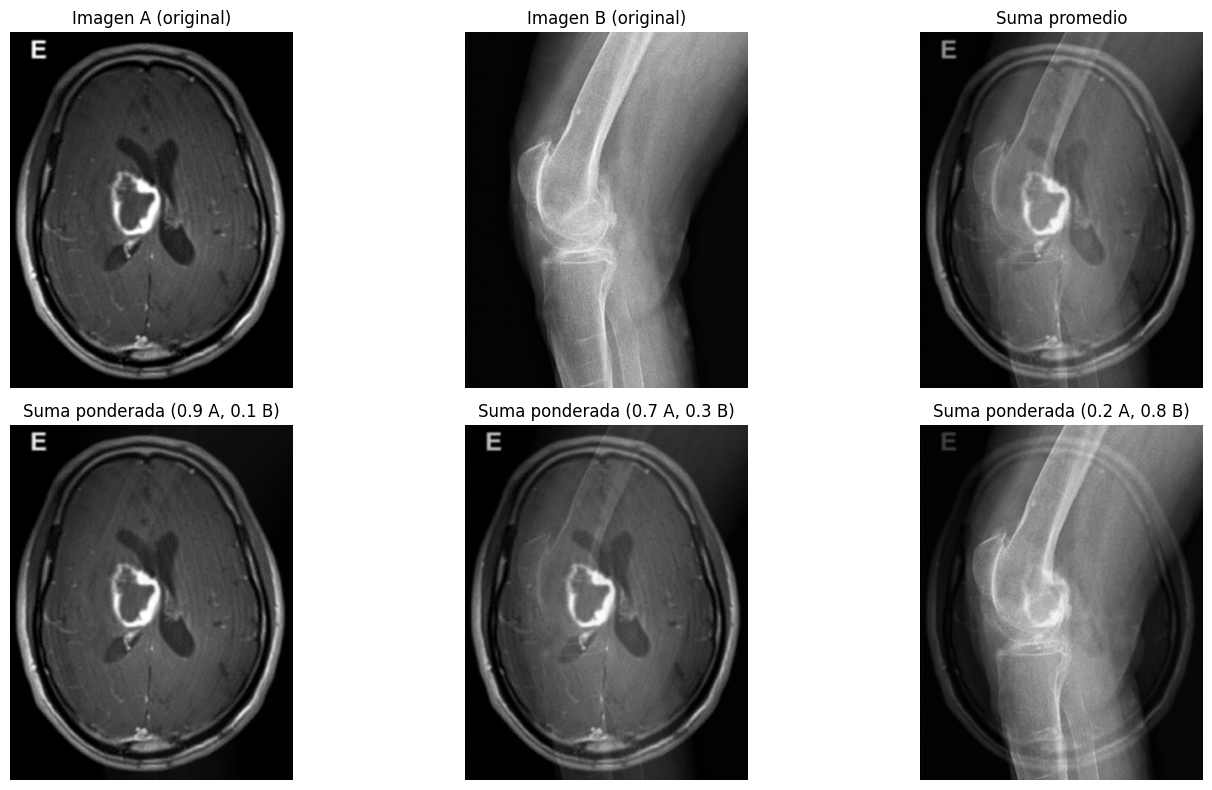

In [4]:
# Suma pnderada con diferentes pesos
suma_90_10 = cv2.addWeighted(img_a, 0.9, img_b, 0.1, 0)
suma_70_30 = cv2.addWeighted(img_a, 0.7, img_b, 0.3, 0)
suma_20_80 = cv2.addWeighted(img_a, 0.2, img_b, 0.8, 0)

# Suma promedio de las dos imágenes (equivalente a una suma ponderada con pesos iguales a 0.5)
suma_promedio = ((img_a.astype(np.float32) + img_b.astype(np.float32)) / 2).astype(np.uint8)

# Mostrar resultados junto con imágenes originales
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(img_a, cmap='gray')
plt.title('Imagen A (original)')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(img_b, cmap='gray')
plt.title('Imagen B (original)')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(suma_promedio, cmap='gray')
plt.title('Suma promedio')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(suma_90_10, cmap='gray')
plt.title('Suma ponderada (0.9 A, 0.1 B)')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(suma_70_30, cmap='gray')
plt.title('Suma ponderada (0.7 A, 0.3 B)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(suma_20_80, cmap='gray')
plt.title('Suma ponderada (0.2 A, 0.8 B)')
plt.axis('off')

plt.tight_layout()
plt.show()

> Para la suma ponderada se utilizó `cv2.addWeighted`, función que calcula `dst = alpha*img_a + beta*img_b + gamma`, saturando automáticamente los valores fuera del rango [0, 255]. Se probaron tres combinaciones distintas de pesos (`alpha`, `beta`): (0.9, 0.1) (0.7, 0.3) y (0.2, 0.8), en donde la imagen con mayor peso predomina visualmente sobre la otra.

> La suma promedio se calculó de forma manual, convirtiendo ambas imágenes a `float32` para evitar que la suma se desborde o se trunque en el tipo `uint8` antes de dividir entre 2, y después regresando el resultado a `uint8`.

**Ejercicio 2. Resta de imágenes**

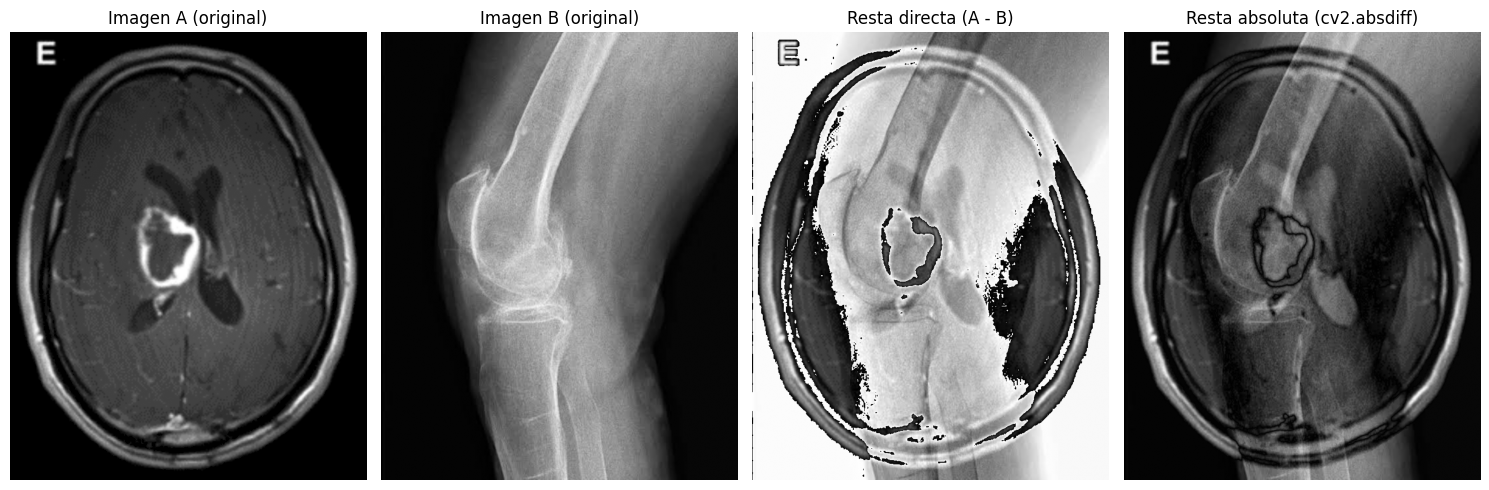

In [5]:
# Resta directa (puede generar wrap-around en valores negativos debido a que son uint8)
resta_directa = img_a - img_b

# Resta en valor absoluto con valor absoluto (cv2.absdiff)
resta_absoluta = cv2.absdiff(img_a, img_b)

# Mostrar resultados junto con imágenes originales
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(img_a, cmap='gray')
plt.title('Imagen A (original)')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(img_b, cmap='gray')
plt.title('Imagen B (original)')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(resta_directa, cmap='gray')
plt.title('Resta directa (A - B)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(resta_absoluta, cmap='gray')
plt.title('Resta absoluta (cv2.absdiff)')
plt.axis('off')

plt.tight_layout()
plt.show()

> La resta directa (`img_a - img_b`) se realiza sobre matrices de tipo `uint8`, por lo que cuando el resultado de un píxel es negativo (es decir, cuando `img_b` es más intenso que `img_a` en esa posición), el valor se desborda ("wrap-around") y vuelve a empezar desde 255 en lugar de truncarse en 0, generando artefactos visuales poco interpretables.

> Para evitar este problema se utilizó `cv2.absdiff`, que calcula el valor absoluto de la diferencia entre ambas imágenes, `|img_a - img_b|`, evitando el desborde numérico. El resultado resalta las regiones donde ambas imágenes difieren más, independientemente de cuál de las dos sea más intensa en cada punto.

**Ejercicio 3. Multiplicación por un factor**

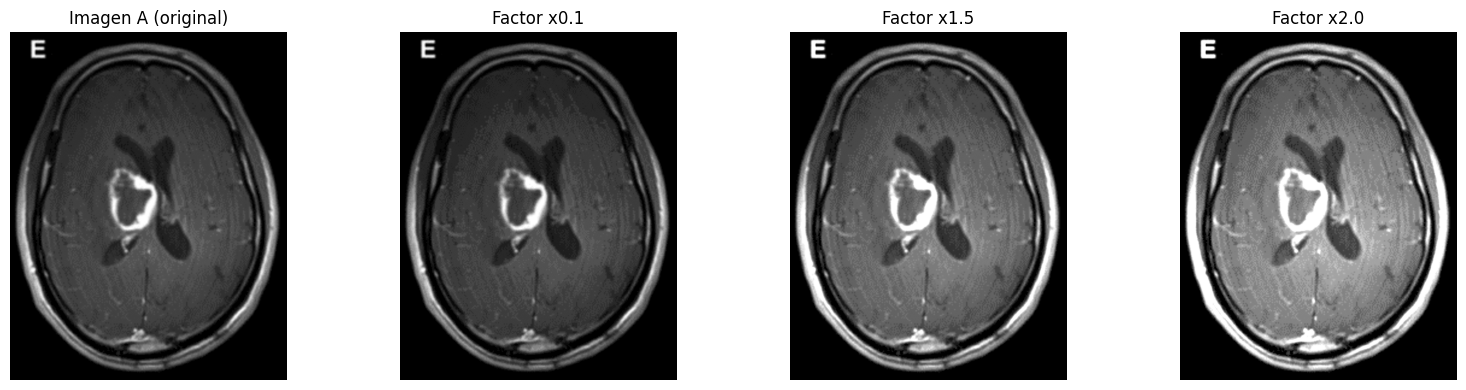

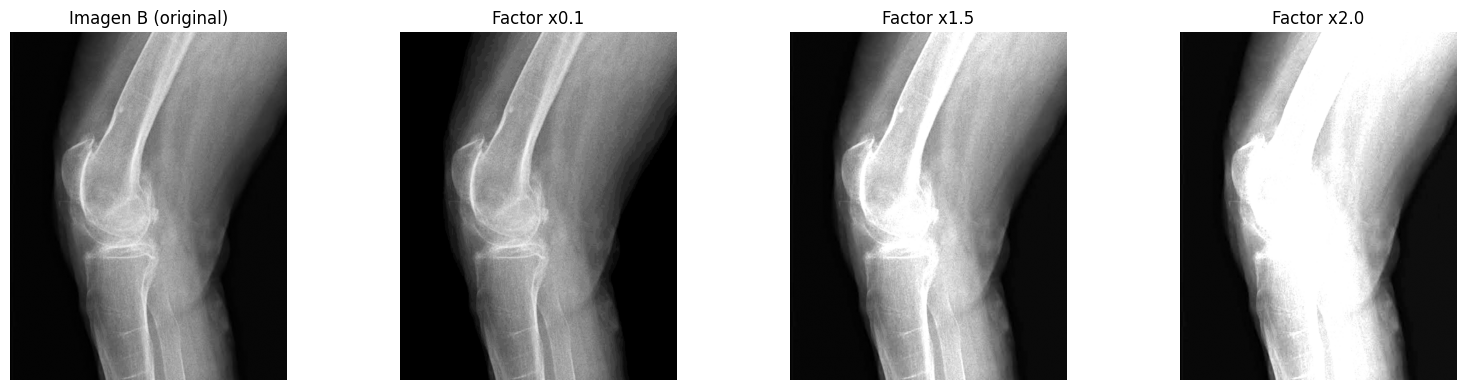

In [7]:
# Factores de multiplicación del brillo
factores = [0.1, 1.5, 2.0]

# Aplicar cada factor a la imagen A
img_a_factores = [np.clip(img_a.astype(np.float32) * f, 0, 255).astype(np.uint8) for f in factores]

# Aplicar cada factor a la imagen B
img_b_factores = [np.clip(img_b.astype(np.float32) * f, 0, 255).astype(np.uint8) for f in factores]

# Mostrar resultados junt con la imagen A original
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_a, cmap='gray')
plt.title('Imagen A (original)')
plt.axis('off')

for i, f in enumerate(factores):
    plt.subplot(1, 4, i + 2)
    plt.imshow(img_a_factores[i], cmap='gray')
    plt.title(f'Factor x{f}')
    plt.axis('off')

plt.tight_layout()
plt.show()

# Mostrar resultados junt con la imagen B original
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_b, cmap='gray')
plt.title('Imagen B (original)')
plt.axis('off')

for i, f in enumerate(factores):
    plt.subplot(1, 4, i + 2)
    plt.imshow(img_b_factores[i], cmap='gray')
    plt.title(f'Factor x{f}')
    plt.axis('off')

plt.tight_layout()
plt.show()

> Para modificar el brillo se multiplicó cada imagen por tres factores distintos (0.1, 1.5 y 2.0), convirtiendo primero la matriz a `float32` para que el resultado de la multiplicación no se trunque antes de aplicar la saturación. Con `np.clip` se limitan los valores resultantes al rango válido [0, 255] antes de regresar la matriz a `uint8`, evitando el desborde que ocurriría si se multiplicara directamente sobre un arreglo de tipo entero sin signo de 8 bits.

> Con un factor menor a 1 (0.1) la imagen se oscurece, mientras que con factores mayores a 1 (1.5 y 2.0) la imagen se aclara progresivamente; con el favtor de (0.1), hay que prestar mucha atención para notar cambios, por otro lado, en factores mayores llegaron incluso a saturarse en las regiones que ya eran muy brillantes en la imagen original.

**Ejercicio 4. Multiplicación elemento por elemento**

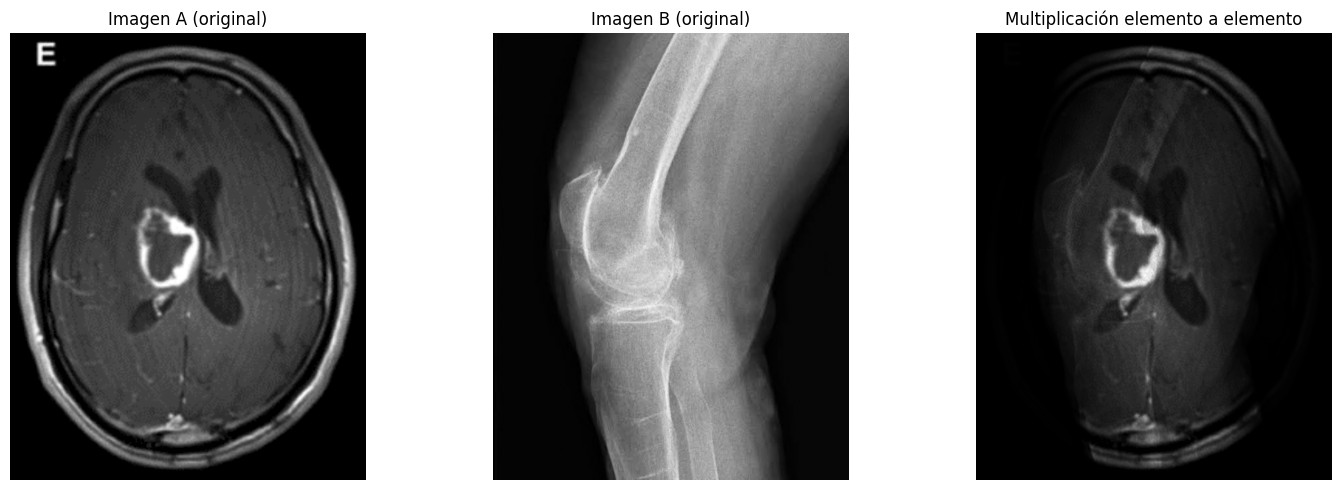

In [8]:
# Normalizar al rango [0, 1] y reescalar el resultado de vuelta a [0, 255] para poder visualizarlo bien
img_a_norm = img_a.astype(np.float32) / 255.0
img_b_norm = img_b.astype(np.float32) / 255.0

mult_pixel = (img_a_norm * img_b_norm * 255).astype(np.uint8)

# Mostrar las imágenes originales y el resultado de la multiplicación
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_a, cmap='gray')
plt.title('Imagen A (original)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_b, cmap='gray')
plt.title('Imagen B (original)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(mult_pixel, cmap='gray')
plt.title('Multiplicación elemento a elemento')
plt.axis('off')

plt.tight_layout()
plt.show()

> La multiplicación elemento por elemento se realizó normalizando ambas imágenes al rango [0, 1] (dividiendo entre 255), multiplicándolas directamente con el operador `*` de NumPy (multiplicación posición a posición, no multiplicación matricial) y reescalando el resultado de vuelta a [0, 255]. Normalizar antes de multiplicar evita que el producto de dos valores altos (por ejemplo 200 x 200) se desborde del rango del `uint8`.

> Esta operación actúa como una especie de "máscara suave": un píxel sólo conserva una intensidad alta en el resultado si ambas imágenes tienen intensidad alta en esa misma posición, mientras que basta con que una de las dos imágenes sea oscura (cercana a 0) en cierta zona para que esa región se oscurezca en el resultado. En aplicaciones biomédicas, esta propiedad resulta útil para enmascarar una imagen con una región de interés (ROI): si se cuenta con una máscara binaria (0 y 1) que delimite, por ejemplo, un tejido u órgano segmentado previamente, al multiplicarla elemento a elemento por la imagen original se conserva únicamente la información de esa región y se elimina (lleva a 0) todo lo que está fuera de ella.

# **Parte II. Operaciones lógicas**

**Ejercicio 1. Ecualización**

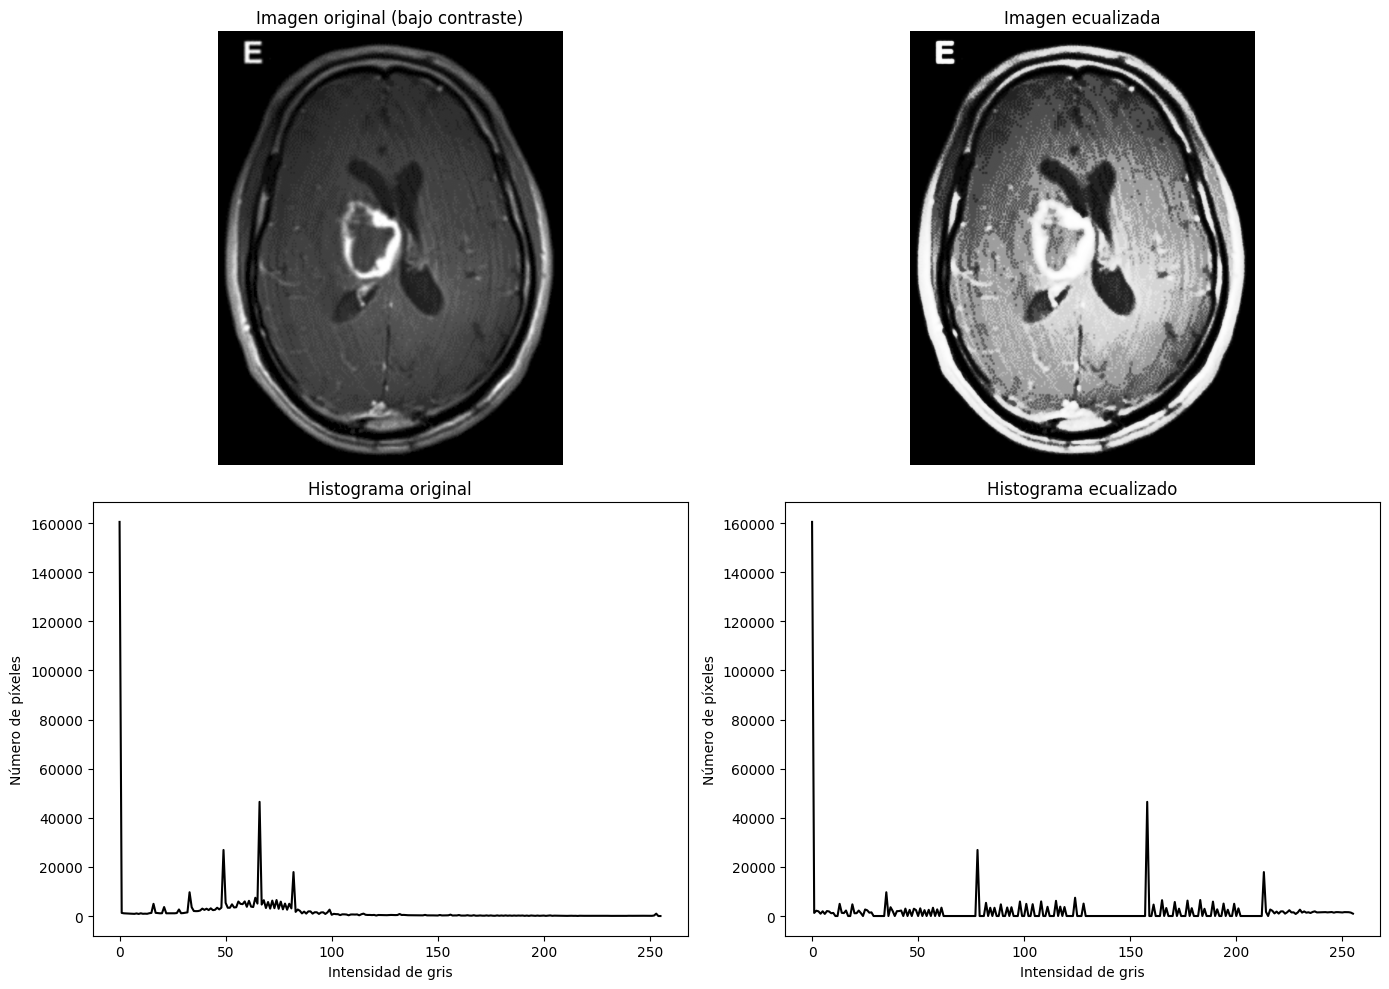

In [10]:
# Obtener el histograma de la imagen de bajo contraste (en este caso elegimos la imagen de la rm)
hist = cv2.calcHist([img_a], [0], None, [256], [0, 256])

# Ecualizar histograma para mejorar el contraste
img_ecualizada = cv2.equalizeHist(img_a)

# Calcular el histograma de la imagen ya ecualizada
hist_ecualizado = cv2.calcHist([img_ecualizada], [0], None, [256], [0, 256])

# Mostrar imagen original, imagen ecualizada y ambos histogramas
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(img_a, cmap='gray')
plt.title('Imagen original (bajo contraste)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(img_ecualizada, cmap='gray')
plt.title('Imagen ecualizada')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.plot(hist, color='black')
plt.title('Histograma original')
plt.xlabel('Intensidad de gris')
plt.ylabel('Número de píxeles')

plt.subplot(2, 2, 4)
plt.plot(hist_ecualizado, color='black')
plt.title('Histograma ecualizado')
plt.xlabel('Intensidad de gris')
plt.ylabel('Número de píxeles')

plt.tight_layout()
plt.show()

> Primero se obtuvo el histograma de la imagen original mediante `cv2.calcHist`, especificando canal único (`[0]`), sin máscara, con intensidad del 0 al 255. En este histograma se observa que los valores de intensidad de la imagen original están concentrados en un rango relativamente reducido, lo cual se refleja visualmente como una imagen de bajo contraste.

> Después se aplicó `cv2.equalizeHist` la cual sirve pra redistribuir los niveles de intensidad de la imagen, de manera que el histograma resultante se aproxime a una distribución uniforme. Al comparar ambos histogramas, se aprecia cómo la ecualización expande el rango dinámico de la imagen, distribuyendo la información en todo el espectro de 0-255 lo que hace una mejoraría visible en el contraste de la imagen médica.